a
a


/home/smidmar9/Projects/Reasearch-task/Research-task/plot_density.py:141: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0,10)


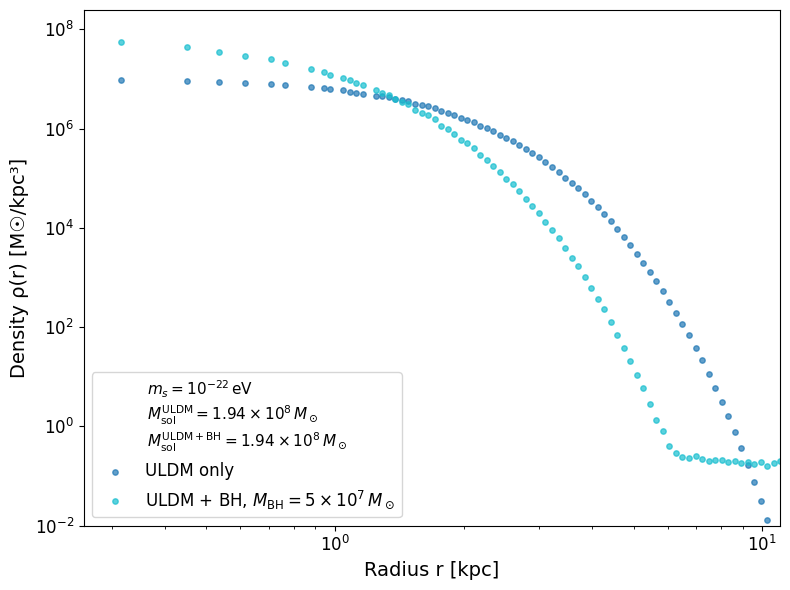

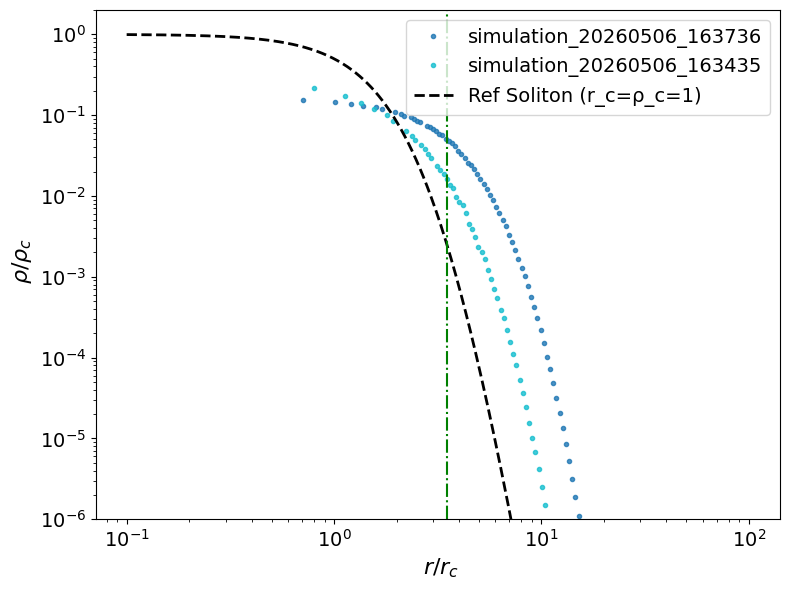

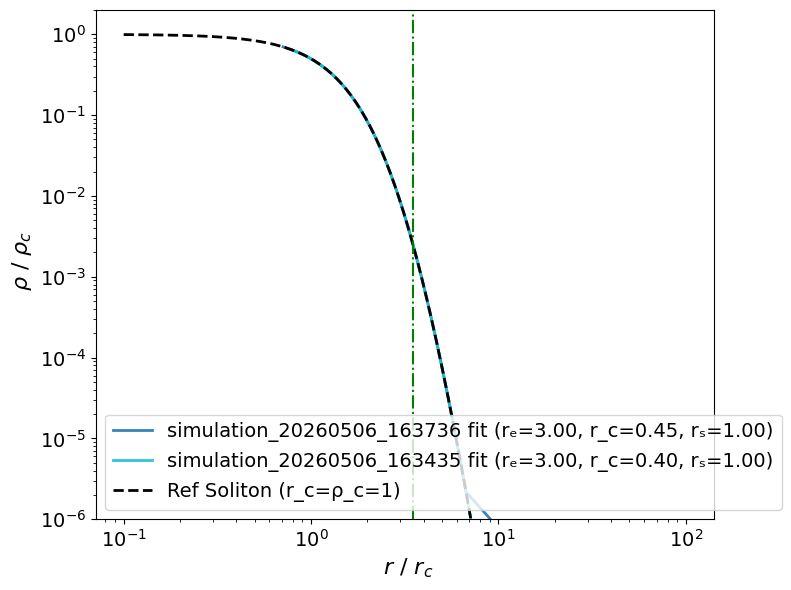

In [20]:
%run plot_density

In [62]:
import numpy as np

stars2 = np.load(f"{snapshot_dir}/baryonic_component_0_Baryons_at_time_20.000000.npz", allow_pickle=True)
stars1 = np.load(f"{snapshot_dir}/baryonic_component_2_Baryons_at_time_20.000000.npz", allow_pickle=True)

stars = {}

for key in stars1.files:
    a = stars1[key]
    b = stars2[key]

    if isinstance(a, np.ndarray) and isinstance(b, np.ndarray) and a.shape != () and b.shape != ():
        stars[key] = np.concatenate([a, b], axis=0)
    else:
        # scalar / metadata: keep from stars1, assuming both are equivalent
        stars[key] = a

In [85]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import yt 
from yt.visualization.volume_rendering.transfer_function_helper import (
    TransferFunctionHelper,
)
import numpy as np
import unyt


snapshot_dir = "resources/data/stable_system"
times_to_plot = [0]

L_full = 100   
L = 50        

Nmesh = 256
shp = (Nmesh, Nmesh, Nmesh)
bbox = np.array([(-L,L),(-L,L),(-L,L)])
data = {}

stars2 = np.load(f"{snapshot_dir}/baryonic_component_0_Baryons_at_time_0.002000.npz", allow_pickle=True)
stars1 = np.load(f"{snapshot_dir}/baryonic_component_0_Baryons_at_time_0.002000.npz", allow_pickle=True)

positions = stars["positions"]      # shape: (N, 3)
velocities = stars["velocities"]    # shape: (N, 3)
m_particle = stars["m_particle"].item()

data['stars', 'particle_position_x'] = (positions[:,0].copy(),'kpc')
data['stars', 'particle_position_y'] = (positions[:,1].copy(),'kpc')
data['stars', 'particle_position_z'] = (positions[:,2].copy(),'kpc')
data['stars', 'particle_velocity_x'] = (velocities[:,0],'kpc/Gyr')
data['stars', 'particle_velocity_y'] = (velocities[:,1],'kpc/Gyr')
data['stars', 'particle_velocity_z'] = (velocities[:,2],'kpc/Gyr')
data['stars', 'mass'] =  (np.ones(positions.shape[0])*m_particle,'Msun')


gas = np.load(f"{snapshot_dir}/baryonic_component_2_NBodyGas_at_time_0.002000.npz", allow_pickle=True)
rho = gas["rho"]
vx = gas["vx"]
vy = gas["vy"]
vz = gas["vz"]
E = gas["E"]
E_radiated = gas["E_radiated"].item()
data['gas','density_gas'] = (rho,'Msun / kpc**3')
data['gas','vx_gas'] = (vx,'kpc / Gyr')
data['gas','vy_gas'] = (vy,'kpc / Gyr')
data['gas','vz_gas'] = (vz,'kpc / Gyr')
data['gas','E'] = (E,'Msun * kpc**2 / Gyr**2') # No idea about units here!


wf = np.load(f"{snapshot_dir}/wf_0_snapshot_at_time_10.000000.npy", allow_pickle=True)
data['gas','density_wave_function'] = (np.abs(wf)**2,'Msun / kpc**3')


ds = yt.load_uniform_grid(data, shp,bbox=bbox,periodicity=[1,1,1],length_unit="kpc", nprocs=1)
def _star_momentum_x(field, data):
    return data["stars", "mass"] * data["stars", "particle_velocity_x"]
def _star_momentum_y(field, data):
    return data["stars", "mass"] * data["stars", "particle_velocity_y"]
def _star_momentum_z(field, data):
    return data["stars", "mass"] * data["stars", "particle_velocity_z"]
ds.add_field(("stars", "momentum_x"), function=_star_momentum_x, sampling_type="particle", units="Msun*kpc/Gyr")
ds.add_field(("stars", "momentum_y"), function=_star_momentum_y, sampling_type="particle", units="Msun*kpc/Gyr")
ds.add_field(("stars", "momentum_z"), function=_star_momentum_z, sampling_type="particle", units="Msun*kpc/Gyr")
ds.add_deposited_particle_field(("stars", "mass"), method="cic")
ds.add_deposited_particle_field(("stars", "momentum_x"), method="cic")
ds.add_deposited_particle_field(("stars", "momentum_y"), method="cic")
ds.add_deposited_particle_field(("stars", "momentum_z"), method="cic")

def _stars_density(field, data):
    return data["deposit", "stars_cic_mass"] / data["index", "cell_volume"]
def _stars_vel_x_cic(field, data):
    mass_on_mesh = data["deposit", "stars_cic_mass"]
    mom_on_mesh = data["deposit", "stars_cic_momentum_x"]
    result = mom_on_mesh / mass_on_mesh
    result[mass_on_mesh == 0] = 0.0
    return result
def _stars_vel_y_cic(field, data):
    mass_on_mesh = data["deposit", "stars_cic_mass"]
    mom_on_mesh = data["deposit", "stars_cic_momentum_y"]
    result = mom_on_mesh / mass_on_mesh
    result[mass_on_mesh == 0] = 0.0
    return result
def _stars_vel_z_cic(field, data):
    mass_on_mesh = data["deposit", "stars_cic_mass"]
    mom_on_mesh = data["deposit", "stars_cic_momentum_z"]
    result = mom_on_mesh / mass_on_mesh
    result[mass_on_mesh == 0] = 0.0
    return result


ds.add_field(name=("stars_cic", "stars_density"),function=_stars_density,sampling_type="local",units="Msun/kpc**3")
ds.add_field(name=("stars_cic", "velocity_x"),function=_stars_vel_x_cic,sampling_type="local",units="kpc/Gyr")
ds.add_field(name=("stars_cic", "velocity_y"),function=_stars_vel_y_cic,sampling_type="local",units="kpc/Gyr")
ds.add_field(name=("stars_cic", "velocity_z"),function=_stars_vel_z_cic,sampling_type="local",units="kpc/Gyr")

field_to_plot = ("gas", "density_wave_function")
field_name = "_".join(field_to_plot)

ad = ds.all_data()

max_info = ad.quantities.max_location(field_to_plot)
max_val = max_info[0]
max_loc = ds.arr(max_info[1:], max_info[1].units)

print(f"maximum of {field_name} is at {max_loc}, value = {max_val}")


# All plots centerd at the max density of the WF
max_loc = ad.quantities.max_location(('gas','density_wave_function'))
max_loc, max_val = ds.arr(max_loc[1:],max_loc[1].units), max_loc[0]
print(f"maximum of {'density'} is at {max_loc}")



yt : [INFO     ] 2026-05-04 21:40:16,405 Parameters: current_time              = 0.0
yt : [INFO     ] 2026-05-04 21:40:16,405 Parameters: domain_dimensions         = [256 256 256]
yt : [INFO     ] 2026-05-04 21:40:16,405 Parameters: domain_left_edge          = [-50. -50. -50.]
yt : [INFO     ] 2026-05-04 21:40:16,406 Parameters: domain_right_edge         = [50. 50. 50.]
yt : [INFO     ] 2026-05-04 21:40:16,406 Parameters: cosmological_simulation   = 0


maximum of gas_density_wave_function is at [0.1953125 0.1953125 0.1953125] code_length, value = 89848306.26678887 Msun/kpc**3
maximum of density is at [0.1953125 0.1953125 0.1953125] code_length


yt : [INFO     ] 2026-05-04 21:49:21,260 Projection completed
yt : [INFO     ] 2026-05-04 21:49:21,260 xlim = -49.804688 50.195312
yt : [INFO     ] 2026-05-04 21:49:21,261 ylim = -49.804688 50.195312
yt : [INFO     ] 2026-05-04 21:49:21,262 xlim = -49.804688 50.195312
yt : [INFO     ] 2026-05-04 21:49:21,262 ylim = -49.804688 50.195312
yt : [INFO     ] 2026-05-04 21:49:21,263 Making a fixed resolution buffer of (('gas', 'density_wave_function')) 800 by 800
yt : [INFO     ] 2026-05-04 21:49:21,548 Saving plot plots/density_map/Projection_gas_density_wave_function.png



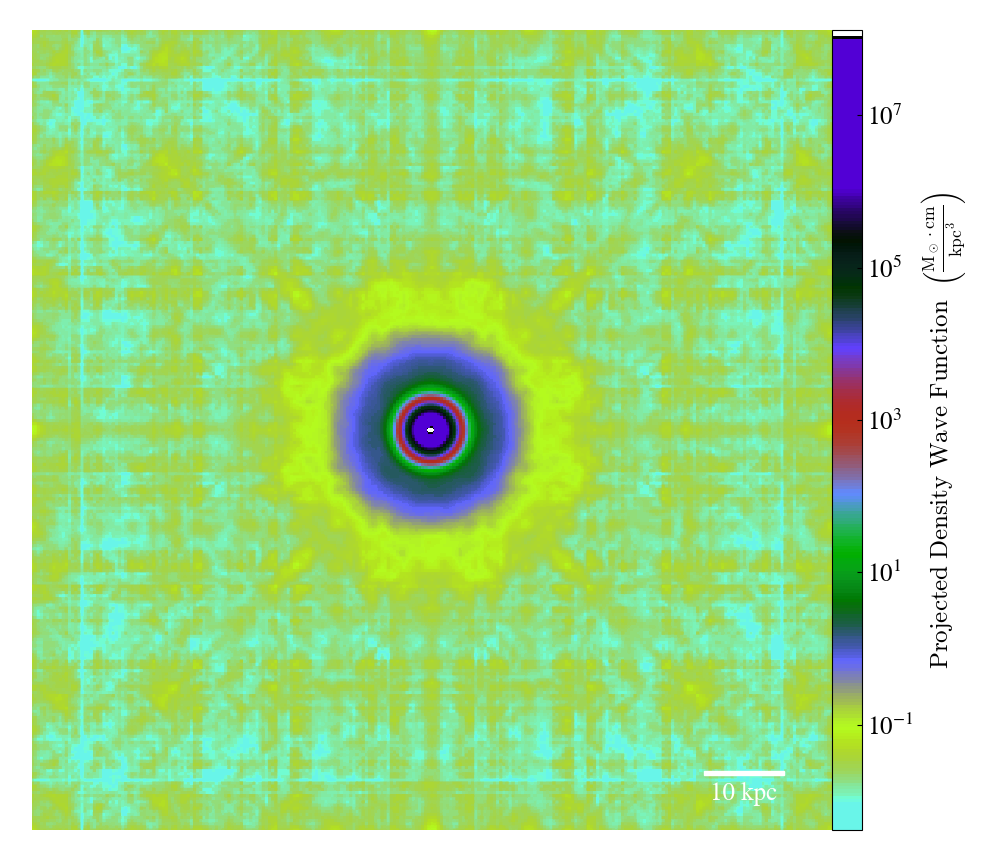

yt : [INFO     ] 2026-05-04 21:49:21,824 xlim = -49.804688 50.195312
yt : [INFO     ] 2026-05-04 21:49:21,824 ylim = -49.804688 50.195312
yt : [INFO     ] 2026-05-04 21:49:21,826 xlim = -49.804688 50.195312
yt : [INFO     ] 2026-05-04 21:49:21,826 ylim = -49.804688 50.195312
yt : [INFO     ] 2026-05-04 21:49:21,827 Making a fixed resolution buffer of (('gas', 'density_wave_function')) 800 by 800
yt : [INFO     ] 2026-05-04 21:49:22,113 Saving plot Slice_gas_density_wave_function.png



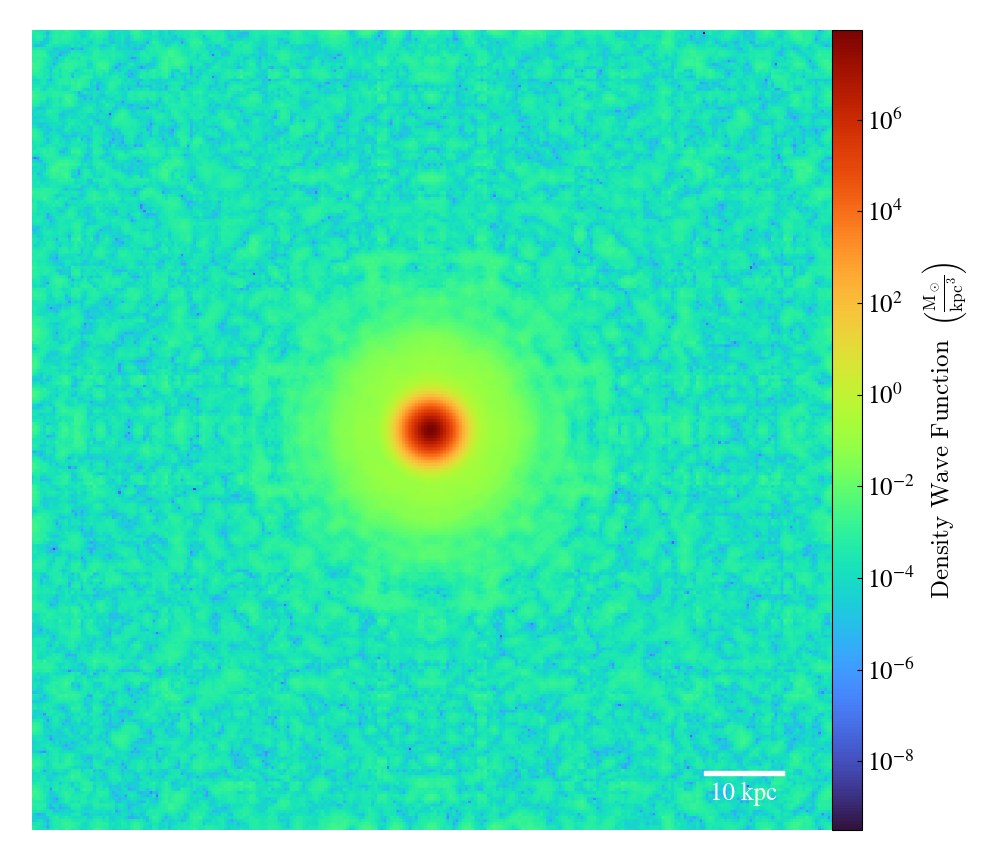

In [90]:
prj = yt.ProjectionPlot(ds, "z", field_to_plot, center=max_loc)
prj.annotate_scale()
prj.hide_axes()
prj.set_cmap(field=field_to_plot, cmap="Nature")
#prj.set_zlim(field_to_plot, 1e2, None)   # nebo 1e3, 1e8 apod.
prj.save(f"plots/density_map/Projection_{field_name}.png")
prj.show()

slc = yt.SlicePlot(ds, "z", field_to_plot, center=max_loc)
slc.annotate_scale()
slc.hide_axes()
slc.set_cmap(field=field_to_plot, cmap="turbo")
# slc.set_log(field_to_plot, False)
# slc.set_zlim(field_to_plot, 1e-2, None)
slc.save(f"Slice_{field_name}.png")
slc.show()

yt : [INFO     ] 2026-05-04 21:06:11,310 Projection completed
yt : [INFO     ] 2026-05-04 21:06:11,311 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:11,311 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:11,313 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:11,313 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:11,313 Making a fixed resolution buffer of (('gas', 'density_wave_function')) 800 by 800



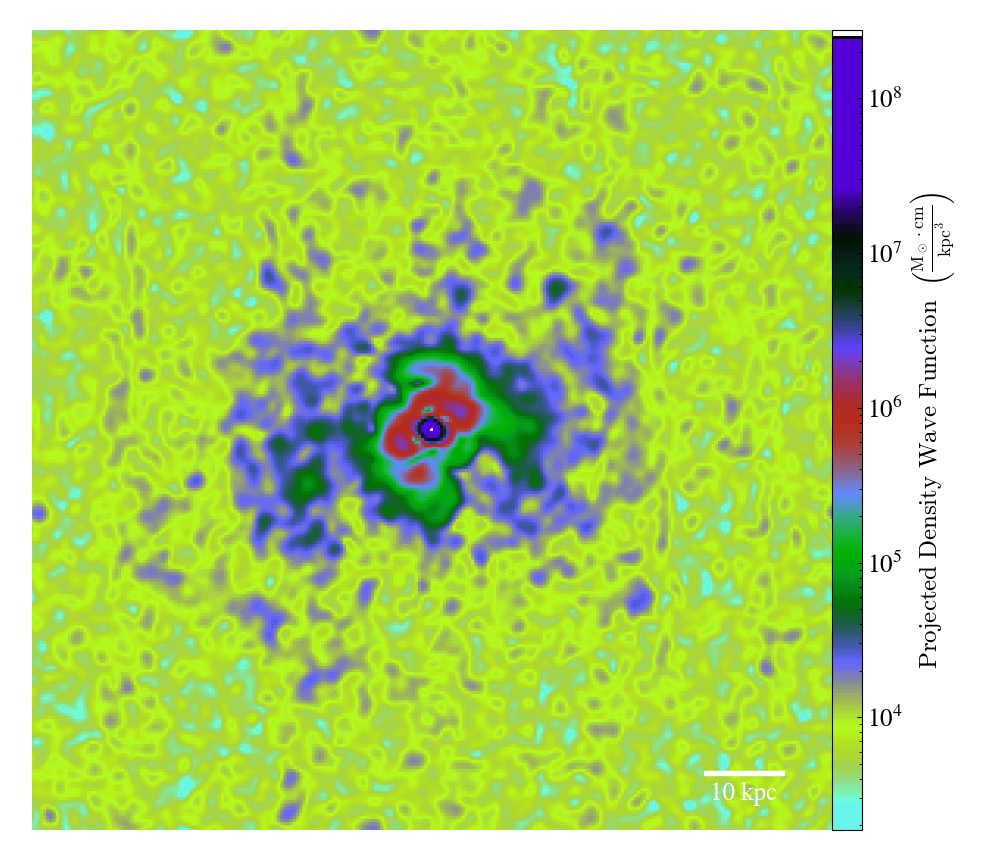

yt : [INFO     ] 2026-05-04 21:06:11,841 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:11,842 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:11,843 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:11,843 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:11,844 Making a fixed resolution buffer of (('gas', 'density_wave_function')) 800 by 800



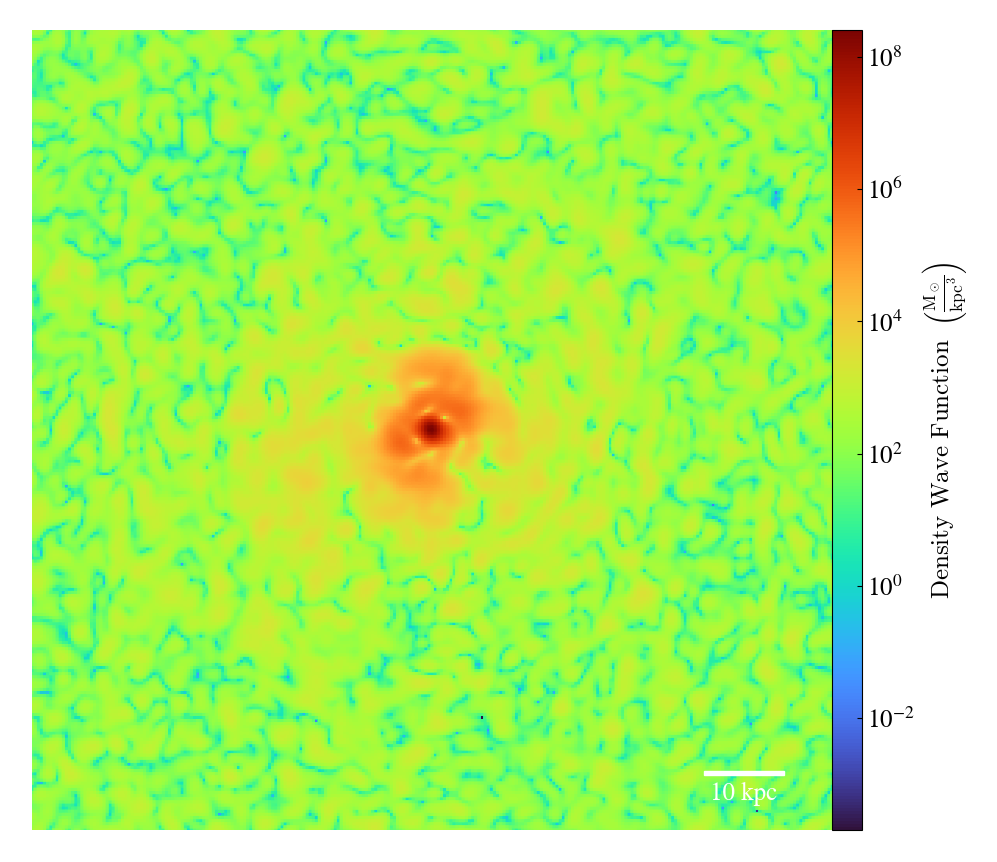

In [65]:


#field_to_plot = ("gas","density_gas")




prj = yt.ProjectionPlot(ds, "z",field_to_plot, 
                    center=max_loc)
prj.annotate_scale()
prj.hide_axes()
prj.set_cmap(field=field_to_plot, cmap="Nature")
#prj.save(f"Projection_{"_".join(field_to_plot)}.png")
prj.show()

slc = yt.SlicePlot(ds, "z",field_to_plot,center=max_loc)
slc.annotate_scale()
slc.hide_axes()
slc.set_cmap(field=field_to_plot, cmap="turbo")
# slc.set_log(field_to_plot, False) # switch to linear scaling
# slc.set_zlim(field_to_plot, 1e-2, None)
#slc.save(f"Slice_{"_".join(field_to_plot)}.png")
slc.show()


yt : [INFO     ] 2026-05-04 21:06:20,565 Projection completed
yt : [INFO     ] 2026-05-04 21:06:20,565 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:20,566 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:20,567 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:20,568 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:20,568 Making a fixed resolution buffer of (('stars_cic', 'stars_density')) 800 by 800



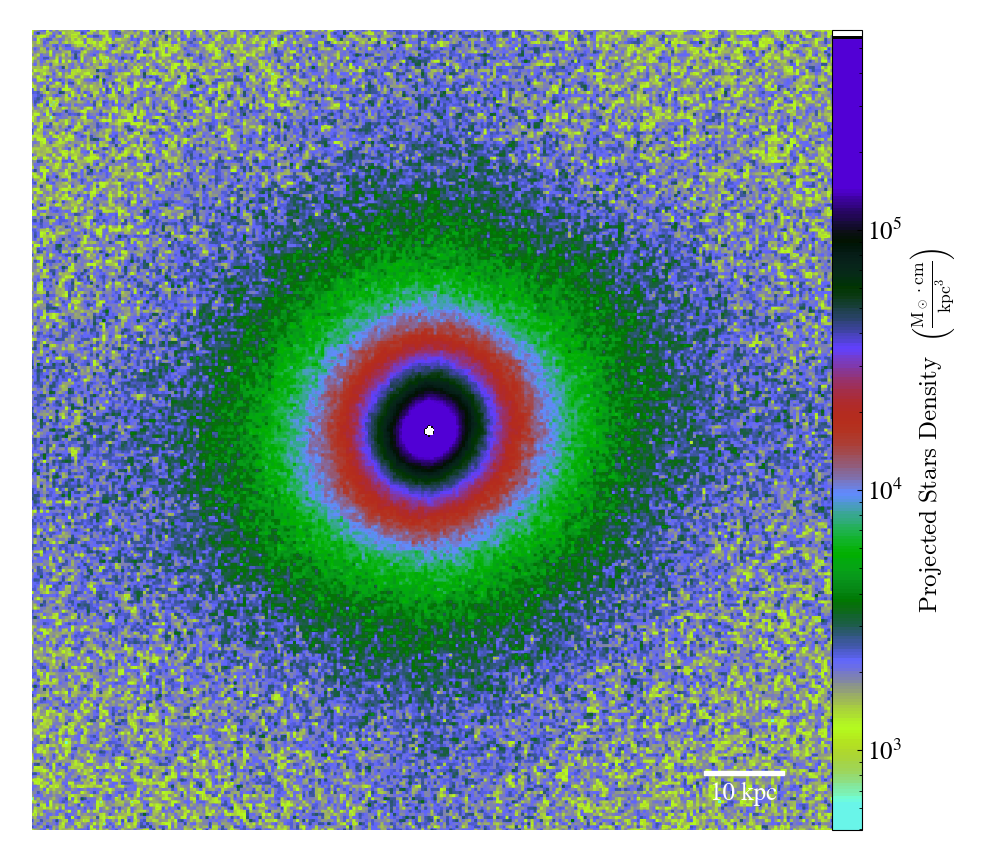

yt : [INFO     ] 2026-05-04 21:06:21,509 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:21,510 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:21,512 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:21,512 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:21,513 Making a fixed resolution buffer of (('stars_cic', 'stars_density')) 800 by 800



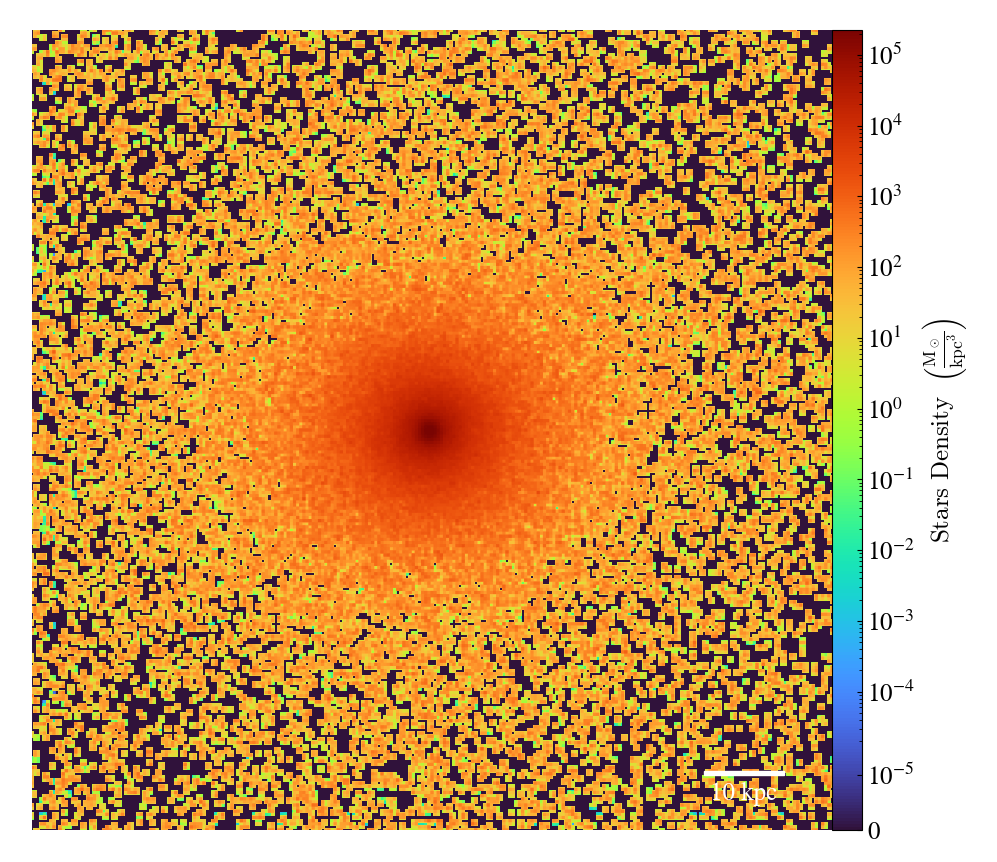

In [66]:


field_to_plot = ("stars_cic","stars_density")




prj = yt.ProjectionPlot(ds, "z",field_to_plot, 
                    center=max_loc)
prj.annotate_scale()
prj.hide_axes()
prj.set_cmap(field=field_to_plot, cmap="Nature")
#prj.save(f"Projection_{"_".join(field_to_plot)}.png")
prj.show()

slc = yt.SlicePlot(ds, "z",field_to_plot,center=max_loc)
slc.annotate_scale()
slc.hide_axes()
slc.set_cmap(field=field_to_plot, cmap="turbo")
# slc.set_log(field_to_plot, False) # switch to linear scaling
# slc.set_zlim(field_to_plot, 1e-2, None)
#slc.save(f"Slice_{"_".join(field_to_plot)}.png")
slc.show()


yt : [INFO     ] 2026-05-04 21:06:32,850 Projection completed
yt : [INFO     ] 2026-05-04 21:06:32,851 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:32,851 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:32,853 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:32,853 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:32,854 Making a fixed resolution buffer of (('gas', 'vz_gas')) 800 by 800



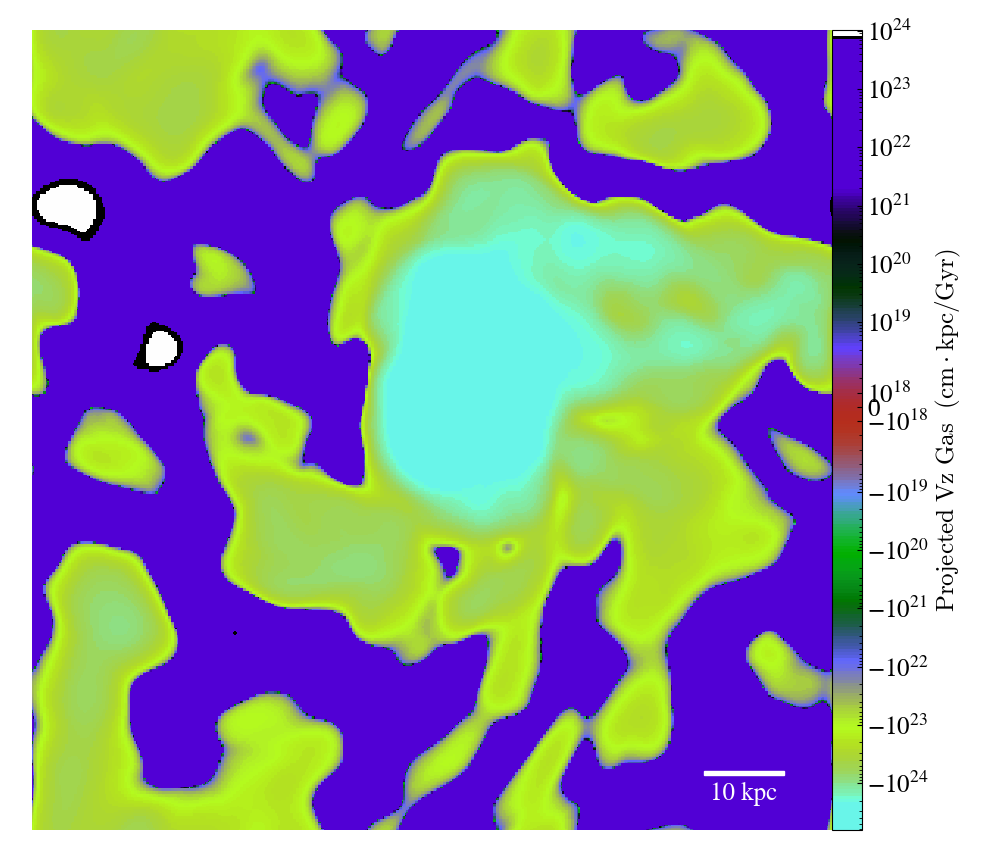

yt : [INFO     ] 2026-05-04 21:06:33,457 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:33,458 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:33,460 xlim = -52.148438 47.851562
yt : [INFO     ] 2026-05-04 21:06:33,460 ylim = -51.367188 48.632812
yt : [INFO     ] 2026-05-04 21:06:33,460 Making a fixed resolution buffer of (('gas', 'vz_gas')) 800 by 800
yt : [INFO     ] 2026-05-04 21:06:33,909 Saving plot plots/velocity_map/velocity_map_4comp_collision_t=0(1).png



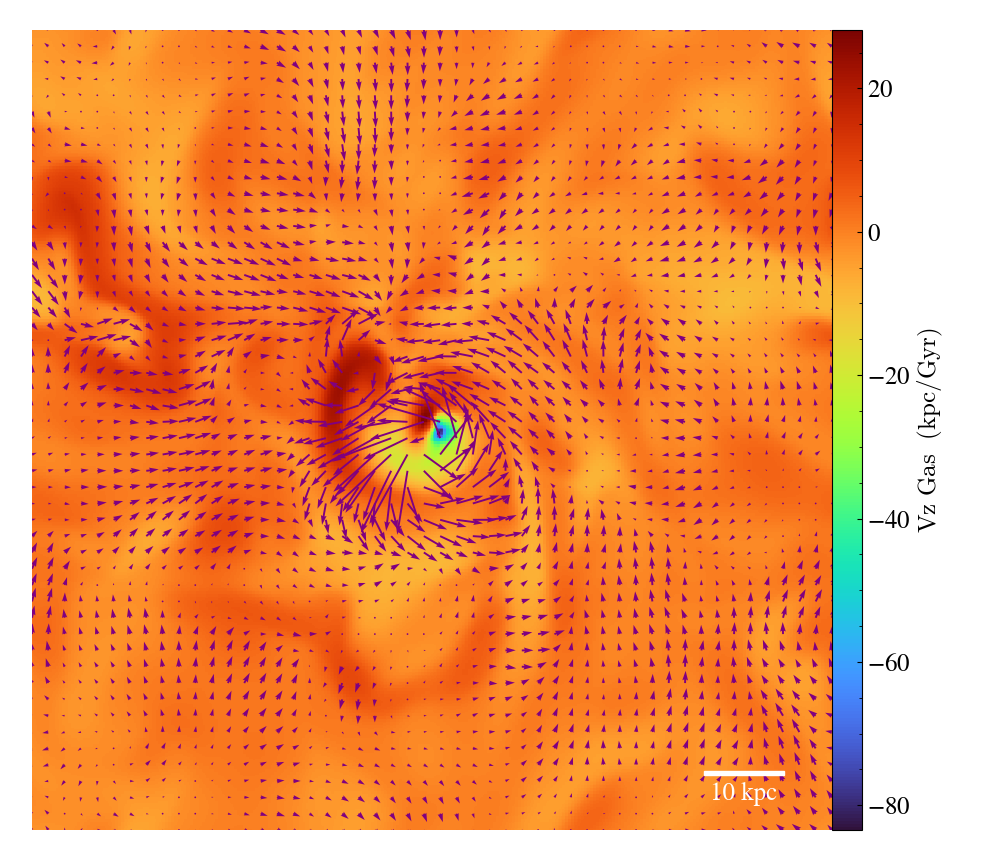

In [67]:
import os

field_to_plot = ("gas", "vz_gas")

save_dir = "plots/velocity_map"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, "velocity_map_4comp_collision_t=0(1).png")

prj = yt.ProjectionPlot(ds, "z", field_to_plot, center=max_loc)
prj.annotate_scale()
prj.hide_axes()
prj.set_cmap(field=field_to_plot, cmap="Nature")
prj.show()

slc = yt.SlicePlot(ds, "z", field_to_plot, center=max_loc)
slc.annotate_scale()
slc.hide_axes()
slc.set_cmap(field=field_to_plot, cmap="turbo")
slc.annotate_quiver(("gas", "vx_gas"), ("gas", "vy_gas"), factor=16, color="purple")
slc.set_log(field_to_plot, False)

slc.save(save_path)
slc.show()

In [53]:


field_to_plot = ("stars_cic", "velocity_z")


prj = yt.ProjectionPlot(ds, "z",field_to_plot, 
                    center=max_loc)
prj.annotate_scale()
# prj.hide_axes()
prj.set_cmap(field=field_to_plot, cmap="Nature")
prj.save(f"Projection_{"_".join(field_to_plot)}.png")
prj.show()

slc = yt.SlicePlot(ds, "z",field_to_plot,center=max_loc)
slc.annotate_scale()
# slc.hide_axes()
slc.set_cmap(field=field_to_plot, cmap="turbo")
slc.set_log(field_to_plot, False) # switch to linear scaling
# slc.set_zlim(field_to_plot, 1e-2, None)
slc.save(f"Slice_{"_".join(field_to_plot)}.png")
slc.show()


SyntaxError: f-string: expecting '}' (411026724.py, line 9)